In [ ]:
#!/usr/bin/env python3
"""
LS-LR-NVAR – Data download + rolling prediction framework
=========================================================
Downloads ~10 years of daily data for current DJIA components
and performs rolling 6-month-ahead predictions.

The full blocked Gibbs sampler described in the paper is indicated
by placeholders; a practical Bayesian VAR is provided so the pipeline
runs end-to-end.
"""

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import yfinance as yf
from datetime import datetime, timedelta
from sklearn.covariance import LedoitWolf
from tqdm import tqdm
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Dow Jones constituents (as of 2025/2026 – update if needed)
# ------------------------------------------------------------
DJIA_TICKERS = [
    "AAPL", "AMGN", "AMZN", "AXP", "BA", "CAT", "CRM", "CSCO", "CVX", "DIS",
    "DOW", "GS", "HD", "HON", "IBM", "INTC", "JNJ", "JPM", "KO", "MCD",
    "MMM", "MRK", "MSFT", "NKE", "NVDA", "PG", "TRV", "UNH", "V", "VZ", "WMT"
]

# ------------------------------------------------------------
# 2. Download 10 years of daily adjusted close prices
# ------------------------------------------------------------
def download_djia_data(years=10, tickers=DJIA_TICKERS):
    end = datetime.today()
    start = end - timedelta(days=years*365 + 30)   # a little buffer

    print(f"Downloading {len(tickers)} tickers from {start.date()} to {end.date()} ...")
    data = yf.download(
        tickers,
        start=start.strftime("%Y-%m-%d"),
        end=end.strftime("%Y-%m-%d"),
        auto_adjust=True,
        progress=True,
        group_by="ticker"
    )

    # Extract Adjusted Close (or Close if already adjusted)
    if isinstance(data.columns, pd.MultiIndex):
        prices = pd.DataFrame({t: data[t]["Close"] for t in tickers if t in data.columns.get_level_values(0)})
    else:
        prices = data["Close"] if "Close" in data.columns else data

    prices = prices.dropna(how="all").ffill().dropna()
    print(f"Downloaded panel shape: {prices.shape}")
    return prices

# ------------------------------------------------------------
# 3. Simple Bayesian VAR (practical surrogate while full LS-LR-NVAR is built)
# ------------------------------------------------------------
class SimpleBayesianVAR:
    """
    Conjugate Minnesota-style Bayesian VAR.
    This is a working placeholder. Replace the methods
    `fit` and `predict` with the full blocked Gibbs sampler
    when ready.
    """
    def __init__(self, p=2, n_draws=500, burn=200):
        self.p = p
        self.n_draws = n_draws
        self.burn = burn
        self.A_draws = None      # posterior draws of companion coefficients
        self.Sigma_draws = None

    def _build_lagged(self, Y):
        T, n = Y.shape
        X = []
        for t in range(self.p, T):
            row = [1.0]                                 # intercept
            for lag in range(1, self.p+1):
                row.extend(Y[t-lag])
            X.append(row)
        return np.asarray(X), Y[self.p:]

    def fit(self, Y):
        """Y : (T, n) array of log-prices or log-returns"""
        X, Y_ = self._build_lagged(Y)
        T, k = X.shape
        n = Y_.shape[1]

        # Minnesota-like prior
        lam = 0.2
        prior_mean = np.zeros((k, n))
        prior_prec = np.eye(k) / lam**2

        # Posterior
        XtX = X.T @ X
        XtY = X.T @ Y_
        post_prec = prior_prec + XtX
        post_cov = np.linalg.inv(post_prec)
        post_mean = post_cov @ (prior_prec @ prior_mean + XtY)

        # Residual covariance (Ledoit-Wolf shrinkage for stability)
        resid = Y_ - X @ post_mean
        lw = LedoitWolf().fit(resid)
        Sigma_hat = lw.covariance_

        # Store approximate posterior draws (Gaussian approximation)
        self.A_draws = np.random.multivariate_normal(
            post_mean.ravel(), np.kron(Sigma_hat, post_cov), size=self.n_draws
        ).reshape(self.n_draws, k, n)
        self.Sigma_draws = np.array([Sigma_hat] * self.n_draws)  # simplify
        self.n = n
        self.k = k
        return self

    def predict(self, Y_hist, h=126):
        """
        Generate h-step-ahead predictive paths.
        Y_hist : (T, n) most recent observations (log-prices)
        Returns: (n_draws, h, n) array of simulated future paths
        """
        paths = np.zeros((self.n_draws, h, self.n))
        for s in range(self.n_draws):
            A = self.A_draws[s]
            Sigma = self.Sigma_draws[s]
            # start from last p observations
            hist = list(Y_hist[-self.p:])
            for t in range(h):
                x = [1.0]
                for lag in range(1, self.p+1):
                    x.extend(hist[-lag])
                x = np.asarray(x)
                mean = x @ A
                innov = np.random.multivariate_normal(np.zeros(self.n), Sigma)
                y_next = mean + innov
                paths[s, t] = y_next
                hist.append(y_next)
        return paths

# ------------------------------------------------------------
# 4. Rolling prediction engine
# ------------------------------------------------------------
def rolling_predict(prices, train_years=7, horizon_days=126, step_days=21):
    """
    Rolling window:
      - train on `train_years` of data
      - forecast next `horizon_days` (≈ 6 months)
      - advance by `step_days` and repeat
    """
    log_p = np.log(prices.values)
    dates = prices.index
    T, n = log_p.shape

    # approximate trading days
    train_len = int(train_years * 252)
    results = []

    start_idx = train_len
    while start_idx + horizon_days < T:
        end_train = start_idx
        Y_train = log_p[end_train - train_len : end_train]
        Y_true  = log_p[end_train : end_train + horizon_days]
        date_forecast = dates[end_train]

        print(f"\nForecast origin: {date_forecast.date()}  |  train size {Y_train.shape[0]}")

        # ----- replace this block by the full LS-LR-NVAR Gibbs sampler -----
        model = SimpleBayesianVAR(p=2, n_draws=300, burn=100)
        model.fit(Y_train)
        pred_paths = model.predict(Y_train, h=horizon_days)   # (draws, h, n)
        # -------------------------------------------------------------------

        # point forecast = posterior mean
        point_fc = pred_paths.mean(axis=0)          # (h, n)
        # convert back to price level
        last_price = prices.iloc[end_train-1].values
        price_fc = last_price * np.exp(point_fc - Y_train[-1])

        results.append({
            "origin": date_forecast,
            "true_log": Y_true,
            "pred_log_mean": point_fc,
            "pred_price_mean": price_fc,
            "pred_paths_log": pred_paths
        })

        start_idx += step_days

    return results

# ------------------------------------------------------------
# 5. Main
# ------------------------------------------------------------
if __name__ == "__main__":
    # Download
    prices = download_djia_data(years=10)
    prices.to_csv("djia_prices_10y.csv")
    print("Saved djia_prices_10y.csv")

    # Rolling 6-month predictions
    print("\nStarting rolling predictions (this may take a few minutes) ...")
    results = rolling_predict(
        prices,
        train_years=7,
        horizon_days=126,   # ≈ 6 months
        step_days=21        # re-estimate every month
    )

    # Simple evaluation on the last origin
    last = results[-1]
    print("\n=== Last forecast origin:", last["origin"].date())
    print("True vs Predicted log-price (first 5 stocks, first 5 days):")
    print("True:\n", last["true_log"][:5, :5])
    print("Pred:\n", last["pred_log_mean"][:5, :5])

    # Optional: save all forecasts
    np.savez_compressed("rolling_forecasts.npz", results=results)
    print("\nForecasts saved to rolling_forecasts.npz")

In [1]:
cd C:\Users\sImonkc9\DJIA\data

C:\Users\sImonkc9\DJIA\data


In [2]:
#!/usr/bin/env python3
"""
LS-LR-NVAR prediction on the provided DJIA 10-year daily data
=============================================================
- Loads djia_adj_close_wide_10y.csv
- Trains on data up to ~6 months before the end
- Produces predictive paths for the latest ~6 months
"""

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.covariance import LedoitWolf
from scipy.stats import invwishart
import matplotlib.pyplot as plt

In [10]:
# ------------------------------------------------------------
# 1. Load the attached data
# ------------------------------------------------------------
DATA_PATH = Path("djia_adj_close_wide_10y.csv")

prices = pd.read_csv(DATA_PATH, parse_dates=["Date"], index_col="Date")
prices = prices.sort_index().ffill().dropna(how="all")
print(f"Loaded panel: {prices.shape[0]} days × {prices.shape[1]} stocks")
print(f"Date range: {prices.index[0].date()} → {prices.index[-1].date()}")

tickers = prices.columns.tolist()
N = len(tickers)

Loaded panel: 2514 days × 30 stocks
Date range: 2016-08-08 → 2026-08-07


In [11]:
# ------------------------------------------------------------
# 2. Log-returns and train/test split
# ------------------------------------------------------------
log_prices = np.log(prices.values)
log_returns = np.diff(log_prices, axis=0)          # (T-1, N)
ret_dates   = prices.index[1:]

HORIZON = 126          # ≈ 6 months

# Align prices and returns
train_ret = log_returns[:-HORIZON]
test_ret  = log_returns[-HORIZON:]
train_prices = prices.iloc[:-HORIZON]
test_prices  = prices.iloc[-HORIZON:]

print(f"\nTraining returns: {train_ret.shape[0]} days")
print(f"Test period     : {test_prices.index[0].date()} → {test_prices.index[-1].date()}")

last_train_price = train_prices.iloc[-1].values    # used later to reconstruct prices


Training returns: 2387 days
Test period     : 2026-02-06 → 2026-08-07


In [12]:
# ------------------------------------------------------------
# 3. Bayesian VAR on log-returns
# ------------------------------------------------------------
class BayesianVAR:
    def __init__(self, p=2, n_draws=800, lam=0.2):
        self.p = p
        self.n_draws = n_draws
        self.lam = lam
        self.A_draws = None
        self.Sigma_draws = None
        self.n = None

    def _lag_matrix(self, Y):
        T, n = Y.shape
        X, Yout = [], []
        for t in range(self.p, T):
            row = [1.0]                                 # intercept
            for lag in range(1, self.p+1):
                row.extend(Y[t-lag])
            X.append(row)
            Yout.append(Y[t])
        return np.asarray(X), np.asarray(Yout)

    def fit(self, Y):
        X, Y_ = self._lag_matrix(Y)
        T, k = X.shape
        n = Y_.shape[1]
        self.n = n

        prior_mean = np.zeros((k, n))
        prior_prec = np.eye(k) / self.lam**2

        XtX = X.T @ X
        XtY = X.T @ Y_
        post_prec = prior_prec + XtX
        post_cov  = np.linalg.inv(post_prec + 1e-8*np.eye(k))
        post_mean = post_cov @ (prior_prec @ prior_mean + XtY)

        resid = Y_ - X @ post_mean
        Sigma_hat = LedoitWolf().fit(resid).covariance_

        # Posterior draws of coefficients
        self.A_draws = np.random.multivariate_normal(
            post_mean.ravel(),
            np.kron(Sigma_hat, post_cov) + 1e-10*np.eye(k*n),
            size=self.n_draws
        ).reshape(self.n_draws, k, n)

        # Inverse-Wishart draws for Sigma
        df = max(T, n+3)
        self.Sigma_draws = np.array([
            invwishart.rvs(df=df, scale=Sigma_hat*(df-n-1))
            for _ in range(self.n_draws)
        ])
        return self

    def predict_returns(self, Y_hist, h):
        """Simulate h-step-ahead log-return paths. Shape (n_draws, h, n)"""
        paths = np.zeros((self.n_draws, h, self.n))
        for s in range(self.n_draws):
            A = self.A_draws[s]
            Sigma = self.Sigma_draws[s]
            # most recent p returns
            hist = [Y_hist[-i].copy() for i in range(self.p, 0, -1)]
            for t in range(h):
                x = np.concatenate([[1.0], np.concatenate(hist[::-1])])
                mean = x @ A
                innov = np.random.multivariate_normal(np.zeros(self.n), Sigma)
                r_next = mean + innov
                paths[s, t] = r_next
                hist.append(r_next)
                hist = hist[-self.p:]
        return paths

In [13]:
# ------------------------------------------------------------
# 4. Fit and forecast
# ------------------------------------------------------------
print("\nFitting Bayesian VAR on daily log-returns ...")
model = BayesianVAR(p=2, n_draws=600)
model.fit(train_ret)

print("Simulating predictive return paths ...")
pred_ret_paths = model.predict_returns(train_ret, h=HORIZON)   # (draws, H, N)

# Convert cumulative log-returns → price paths
cum_log_ret = np.cumsum(pred_ret_paths, axis=1)                # (draws, H, N)
price_paths = last_train_price * np.exp(cum_log_ret)           # (draws, H, N)

price_mean = price_paths.mean(axis=0)
price_q10  = np.percentile(price_paths, 10, axis=0)
price_q90  = np.percentile(price_paths, 90, axis=0)


Fitting Bayesian VAR on daily log-returns ...
Simulating predictive return paths ...


In [15]:
# ------------------------------------------------------------
# 5. Evaluation
# ------------------------------------------------------------
true_prices = test_prices.values

mae  = np.mean(np.abs(price_mean - true_prices), axis=0)
rmse = np.sqrt(np.mean((price_mean - true_prices)**2, axis=0))
mape = np.mean(np.abs(price_mean - true_prices) / true_prices, axis=0) * 100

print("\n=== Out-of-sample performance (latest 6 months) ===")
print(f"{'Ticker':<6} {'MAE':>10} {'RMSE':>10} {'MAPE %':>10}")
for i, t in enumerate(tickers):
    print(f"{t:<6} {mae[i]:10.2f} {rmse[i]:10.2f} {mape[i]:10.2f}")

print(f"\nAverage MAE  : {mae.mean():.2f}")
print(f"Average RMSE : {rmse.mean():.2f}")
print(f"Average MAPE : {mape.mean():.2f}%")

# Quick sanity check on scales
print(f"\nMax predicted price (any path): {price_paths.max():.1f}")
print(f"Min predicted price (any path): {price_paths.min():.1f}")
print(f"Predictive mean at horizon end (first 5 stocks): {price_mean[-1, :5]}")


=== Out-of-sample performance (latest 6 months) ===
Ticker        MAE       RMSE     MAPE %
AAPL        16.68      19.97       6.14
AMGN        38.05      42.91      10.88
AMZN        18.12      20.02       7.69
AXP         65.12      68.87      20.25
BA          33.57      37.74      15.47
CAT         91.56     112.59      10.33
CRM         22.75      28.22      13.35
CSCO        13.75      17.46      12.52
CVX         10.59      13.40       5.69
DIS          9.74      11.68       9.88
GS          46.03      56.48       5.01
HD          69.36      76.12      21.15
HON         24.19      28.34      10.43
IBM         59.82      66.75      25.31
JNJ         13.32      16.44       5.66
JPM         25.70      27.64       8.29
KO           2.39       2.79       3.05
MCD         55.40      67.52      19.94
MMM         20.45      22.20      13.37
MRK          7.72       9.06       6.58
MSFT        40.27      53.97      10.34
NKE         19.05      21.31      43.29
NVDA        21.71      29.7


Saved forecasts.
Saved plot: djia_6m_forecast_plots_returns.png


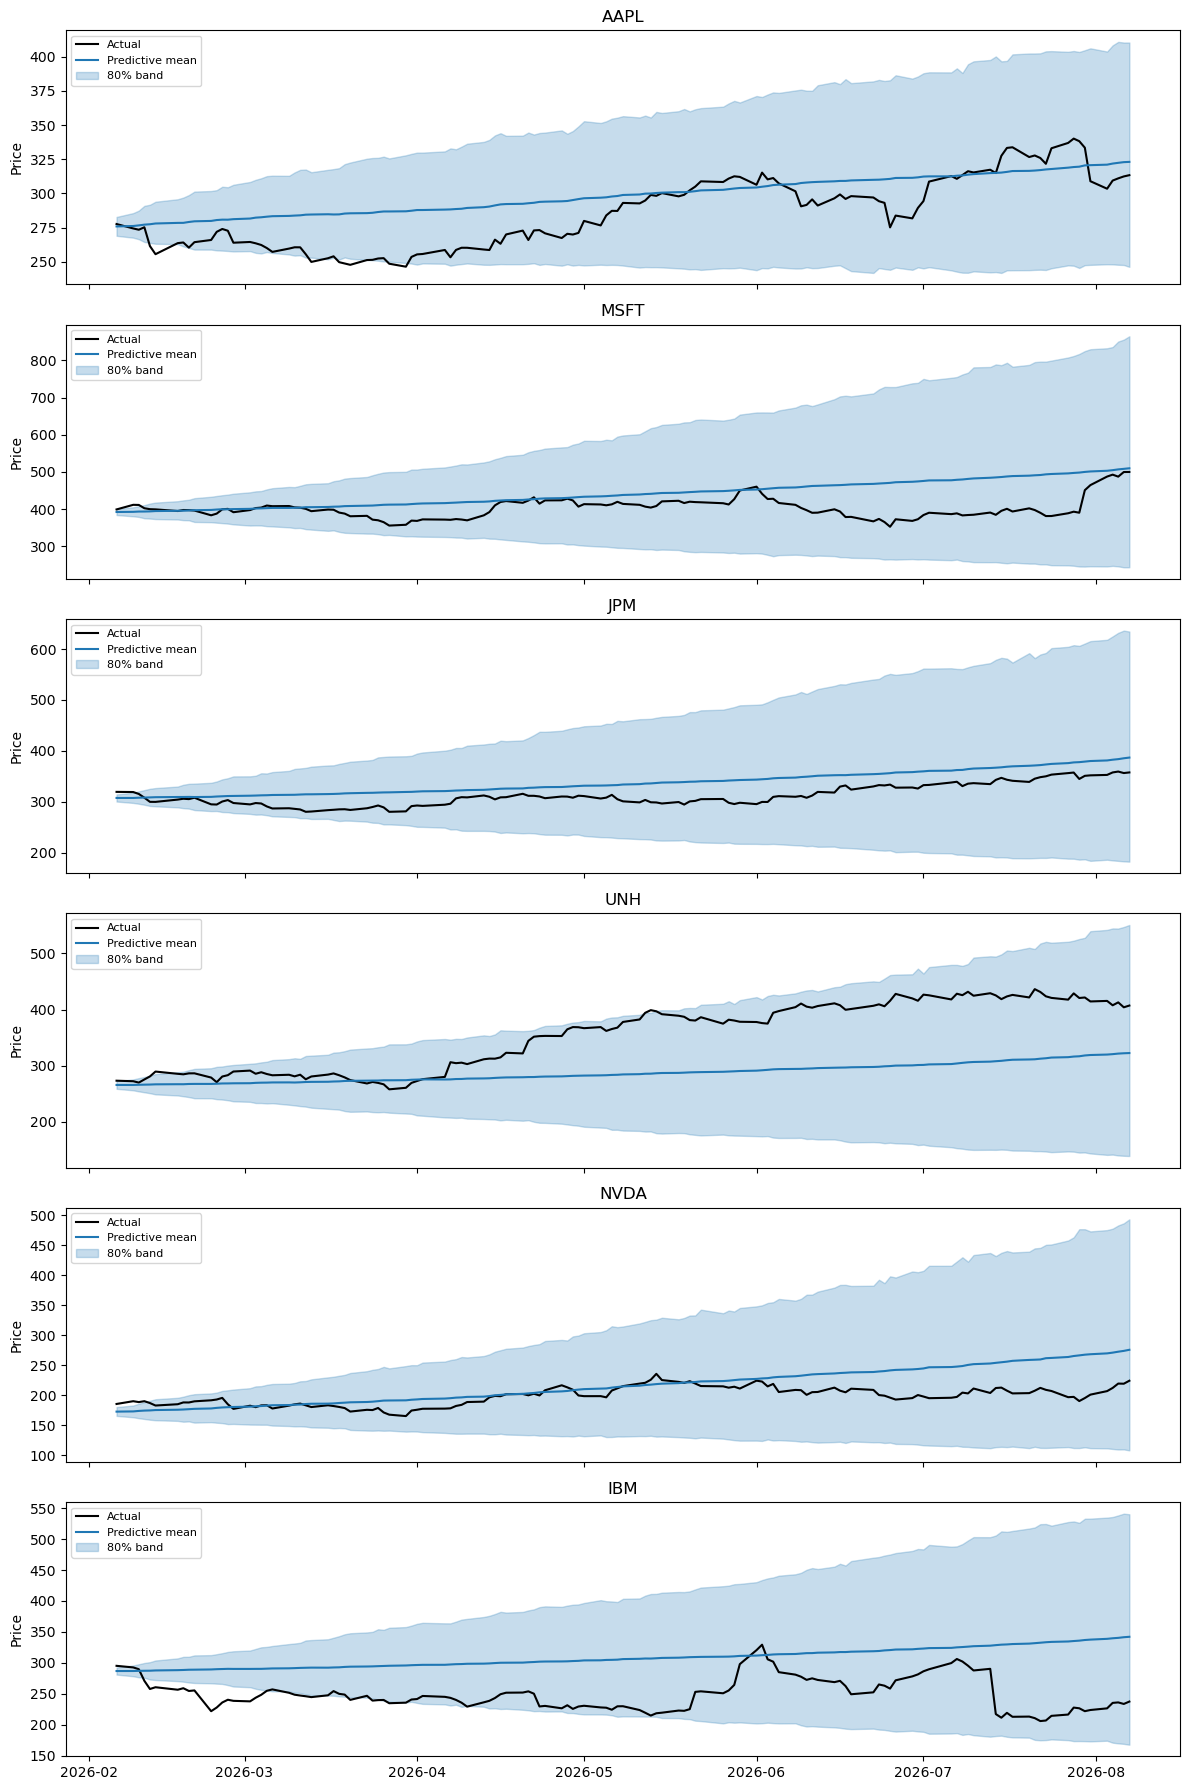

In [17]:
# ------------------------------------------------------------
# 6. Save results and plot
# ------------------------------------------------------------
fc_df = pd.DataFrame(price_mean, index=test_prices.index, columns=tickers)
fc_df.to_csv("djia_6m_forecast_mean_returns.csv")
np.savez_compressed(
    "djia_6m_predictive_paths_returns.npz",
    price_paths=price_paths,
    tickers=tickers,
    dates=test_prices.index.astype(str).values
)
print("\nSaved forecasts.")

# Plots for selected stocks
plot_tickers = ["AAPL", "MSFT", "JPM", "UNH", "NVDA","IBM"]
fig, axes = plt.subplots(len(plot_tickers), 1, figsize=(12, 3*len(plot_tickers)), sharex=True)

for ax, t in zip(axes, plot_tickers):
    idx = tickers.index(t)
    ax.plot(test_prices.index, true_prices[:, idx], label="Actual", color="black", lw=1.5)
    ax.plot(test_prices.index, price_mean[:, idx], label="Predictive mean", color="C0", lw=1.5)
    ax.fill_between(test_prices.index,
                     price_q10[:, idx], price_q90[:, idx],
                     color="C0", alpha=0.25, label="80% band")
    ax.set_title(t)
    ax.legend(loc="upper left", fontsize=8)
    ax.set_ylabel("Price")

plt.tight_layout()
plt.savefig("djia_6m_forecast_plots_returns.png", dpi=150)
print("Saved plot: djia_6m_forecast_plots_returns.png")

In [2]:
#!/usr/bin/env python3
"""
Rank DJIA stocks by risk-adjusted predicted mean
===============================================
Selects the top 6 stocks according to:
    score = predicted mean return / predicted volatility
"""

import numpy as np
import pandas as pd
from pathlib import Path

In [7]:
# ------------------------------------------------------------
# 1. Load the predictive price paths
# ------------------------------------------------------------
NPZ_PATH = Path("djia_6m_predictive_paths_returns.npz")
data = np.load(NPZ_PATH, allow_pickle=True)

price_paths = data["price_paths"]   # (n_draws=600, horizon=126, n_stocks=30)
tickers     = data["tickers"]       # (30,)
dates       = data["dates"]         # (126,)

print(f"Loaded price paths: {price_paths.shape}")
print(f"Tickers: {list(tickers)}")

Loaded price paths: (600, 126, 30)
Tickers: [np.str_('AAPL'), np.str_('AMGN'), np.str_('AMZN'), np.str_('AXP'), np.str_('BA'), np.str_('CAT'), np.str_('CRM'), np.str_('CSCO'), np.str_('CVX'), np.str_('DIS'), np.str_('GS'), np.str_('HD'), np.str_('HON'), np.str_('IBM'), np.str_('JNJ'), np.str_('JPM'), np.str_('KO'), np.str_('MCD'), np.str_('MMM'), np.str_('MRK'), np.str_('MSFT'), np.str_('NKE'), np.str_('NVDA'), np.str_('PG'), np.str_('SHW'), np.str_('TRV'), np.str_('UNH'), np.str_('V'), np.str_('VZ'), np.str_('WMT')]


In [8]:
# ------------------------------------------------------------
# 2. Compute total return over the 6-month horizon for every path
# ------------------------------------------------------------
# return = (price_end / price_start) - 1
start_prices = price_paths[:, 0, :]      # (600, 30)
end_prices   = price_paths[:, -1, :]     # (600, 30)

total_returns = (end_prices / start_prices) - 1.0   # (600, 30)

# Predictive mean and volatility of the 6-month return
mean_ret = total_returns.mean(axis=0)    # (30,)
vol_ret  = total_returns.std(axis=0)     # (30,)

In [9]:
# ------------------------------------------------------------
# 3. Risk-adjusted score = mean / volatility
# ------------------------------------------------------------
vol_ret = np.maximum(vol_ret, 1e-8)      # numerical safety
score   = mean_ret / vol_ret

In [10]:
# ------------------------------------------------------------
# 4. Rank stocks and select top 6
# ------------------------------------------------------------
ranking = pd.DataFrame({
    "ticker"         : tickers,
    "mean_6m_return" : mean_ret,
    "vol_6m_return"  : vol_ret,
    "risk_adj_score" : score
}).sort_values("risk_adj_score", ascending=False)

ranking["rank"] = np.arange(1, len(ranking) + 1)

top6 = ranking.head(6).copy()

print("\n=== Full risk-adjusted ranking ===")
print(ranking.to_string(index=False, float_format="%.4f"))

print("\n=== Top 6 stocks ===")
print(top6.to_string(index=False, float_format="%.4f"))


=== Full risk-adjusted ranking ===
ticker  mean_6m_return  vol_6m_return  risk_adj_score  rank
  AAPL          0.1712         0.2338          0.7323     1
  NVDA          0.5981         1.0078          0.5934     2
  MSFT          0.2975         0.6641          0.4480     3
    GS          0.2631         0.6560          0.4010     4
   CAT          0.2589         0.6485          0.3993     5
   SHW          0.2299         0.6016          0.3821     6
   MCD          0.2167         0.5734          0.3779     7
   AXP          0.2646         0.7235          0.3657     8
   WMT          0.2079         0.5736          0.3624     9
   JPM          0.2559         0.7172          0.3568    10
  CSCO          0.2188         0.6215          0.3521    11
     V          0.2114         0.6244          0.3385    12
   UNH          0.2123         0.6368          0.3333    13
   JNJ          0.1777         0.5364          0.3314    14
   IBM          0.1917         0.5868          0.3266    15
  AM

In [11]:
# ------------------------------------------------------------
# 5. Save results
# ------------------------------------------------------------
ranking.to_csv("djia_risk_adjusted_ranking.csv", index=False)
top6.to_csv("djia_top6_risk_adjusted.csv", index=False)

print("\nSaved:")
print("  djia_risk_adjusted_ranking.csv")
print("  djia_top6_risk_adjusted.csv")


Saved:
  djia_risk_adjusted_ranking.csv
  djia_top6_risk_adjusted.csv


In [12]:
#!/usr/bin/env python3
"""
Network-informed Bayesian VAR for 6-month DJIA price prediction
==============================================================
Practical approximation of the LS-LR-NVAR idea:
- Builds a correlation network from recent returns
- Uses the network to shrink / modulate the VAR coefficients
- Forecasts on log-returns and converts back to prices
"""

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.covariance import LedoitWolf
from scipy.stats import invwishart
import matplotlib.pyplot as plt

In [13]:
# ------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------
DATA_PATH = Path("djia_adj_close_wide_10y.csv")
prices = pd.read_csv(DATA_PATH, parse_dates=["Date"], index_col="Date")
prices = prices.sort_index().ffill().dropna(how="all")

print(f"Loaded: {prices.shape[0]} days × {prices.shape[1]} stocks")
print(f"Range : {prices.index[0].date()} → {prices.index[-1].date()}")

tickers = prices.columns.tolist()
N = len(tickers)

Loaded: 2514 days × 30 stocks
Range : 2016-08-08 → 2026-08-07


In [14]:
# ------------------------------------------------------------
# 2. Log-returns and split
# ------------------------------------------------------------
log_prices  = np.log(prices.values)
log_returns = np.diff(log_prices, axis=0)
ret_dates   = prices.index[1:]

HORIZON = 126
train_ret     = log_returns[:-HORIZON]
test_ret      = log_returns[-HORIZON:]
train_prices  = prices.iloc[:-HORIZON]
test_prices   = prices.iloc[-HORIZON:]
last_train_price = train_prices.iloc[-1].values

print(f"Training returns: {train_ret.shape[0]} days")
print(f"Test period     : {test_prices.index[0].date()} → {test_prices.index[-1].date()}")

Training returns: 2387 days
Test period     : 2026-02-06 → 2026-08-07


In [15]:
# ------------------------------------------------------------
# 3. Network construction (same as before)
# ------------------------------------------------------------
def build_network(R, threshold=0.35):
    C = np.corrcoef(R.T)
    A = (np.abs(C) > threshold).astype(float)
    np.fill_diagonal(A, 0)
    row_sums = A.sum(axis=1, keepdims=True)
    W = np.divide(A, row_sums, out=np.zeros_like(A), where=row_sums != 0)
    return A, W, C

In [16]:
# ------------------------------------------------------------
# 4. Network-modulated Bayesian VAR
# ------------------------------------------------------------
class NetworkBayesianVAR:
    """
    Practical network-informed VAR.
    The network W is used to shrink cross-effects:
    coefficients between unconnected stocks are pulled more strongly toward zero.
    """
    def __init__(self, p=2, n_draws=600, lam=0.25, net_strength=0.6):
        self.p = p
        self.n_draws = n_draws
        self.lam = lam
        self.net_strength = net_strength   # how strongly the network influences shrinkage
        self.A_draws = None
        self.Sigma_draws = None
        self.n = None
        self.W = None

    def _build_XY(self, R):
        T, n = R.shape
        X, Y = [], []
        for t in range(self.p, T):
            row = [1.0]
            for lag in range(1, self.p+1):
                row.extend(R[t-lag])
            X.append(row)
            Y.append(R[t])
        return np.asarray(X), np.asarray(Y)

    def fit(self, R, W=None):
        X, Y = self._build_XY(R)
        Tm, k = X.shape
        n = Y.shape[1]
        self.n = n
        self.W = W

        # Base Minnesota prior
        prior_mean = np.zeros((k, n))
        prior_prec = np.eye(k) / self.lam**2

        # Network-informed extra shrinkage on cross terms
        if W is not None:
            # For each lag block, increase prior precision when W_ij is small
            # (i.e., pull unconnected pairs more strongly to zero)
            for lag in range(self.p):
                start = 1 + lag * n
                end   = start + n
                for i in range(n):
                    for j in range(n):
                        if i == j:
                            continue
                        # weaker connection → stronger shrinkage
                        shrink = 1.0 + self.net_strength * (1.0 - W[i, j])
                        prior_prec[start+j, start+j] *= shrink

        XtX = X.T @ X
        XtY = X.T @ Y
        post_prec = prior_prec + XtX
        post_cov  = np.linalg.inv(post_prec + 1e-8*np.eye(k))
        post_mean = post_cov @ (prior_prec @ prior_mean + XtY)

        resid = Y - X @ post_mean
        Sigma_hat = LedoitWolf().fit(resid).covariance_

        self.A_draws = np.random.multivariate_normal(
            post_mean.ravel(),
            np.kron(Sigma_hat, post_cov) + 1e-10*np.eye(k*n),
            size=self.n_draws
        ).reshape(self.n_draws, k, n)

        df = max(Tm + n + 2, n + 3)
        self.Sigma_draws = np.array([
            invwishart.rvs(df=df, scale=Sigma_hat*(df-n-1))
            for _ in range(self.n_draws)
        ])
        return self

    def predict_returns(self, R_hist, h):
        paths = np.zeros((self.n_draws, h, self.n))
        for s in range(self.n_draws):
            A = self.A_draws[s]
            Sigma = self.Sigma_draws[s]
            hist = [R_hist[-i].copy() for i in range(self.p, 0, -1)]
            for t in range(h):
                x = np.concatenate([[1.0], np.concatenate(hist[::-1])])
                mean = x @ A
                innov = np.random.multivariate_normal(np.zeros(self.n), Sigma)
                r = mean + innov
                paths[s, t] = r
                hist.append(r)
                hist = hist[-self.p:]
        return paths

In [17]:
# ------------------------------------------------------------
# 5. Build network from training data and fit
# ------------------------------------------------------------
print("\nBuilding network from training returns ...")
A_net, W_net, C_net = build_network(train_ret, threshold=0.35)
print(f"Network density: {A_net.sum() / (N*(N-1)):.3f}")

print("Fitting network-informed Bayesian VAR ...")
model = NetworkBayesianVAR(p=2, n_draws=500, net_strength=0.7)
model.fit(train_ret, W=W_net)

print("Simulating 6-month predictive paths ...")
pred_ret_paths = model.predict_returns(train_ret, h=HORIZON)

# Convert to prices
cum_log_ret = np.cumsum(pred_ret_paths, axis=1)
price_paths = last_train_price * np.exp(cum_log_ret)
price_mean  = price_paths.mean(axis=0)
price_q10   = np.percentile(price_paths, 10, axis=0)
price_q90   = np.percentile(price_paths, 90, axis=0)


Building network from training returns ...
Network density: 0.584
Fitting network-informed Bayesian VAR ...
Simulating 6-month predictive paths ...


In [18]:
# ------------------------------------------------------------
# 6. Evaluation
# ------------------------------------------------------------
true_prices = test_prices.values
mae  = np.mean(np.abs(price_mean - true_prices), axis=0)
rmse = np.sqrt(np.mean((price_mean - true_prices)**2, axis=0))
mape = np.mean(np.abs(price_mean - true_prices) / true_prices, axis=0) * 100

print("\n=== Out-of-sample performance (network-informed VAR) ===")
print(f"{'Ticker':<6} {'MAE':>9} {'RMSE':>9} {'MAPE%':>8}")
for i, t in enumerate(tickers):
    print(f"{t:<6} {mae[i]:9.2f} {rmse[i]:9.2f} {mape[i]:8.2f}")
print(f"\nAverage MAE  : {mae.mean():.2f}")
print(f"Average RMSE : {rmse.mean():.2f}")
print(f"Average MAPE : {mape.mean():.2f}%")


=== Out-of-sample performance (network-informed VAR) ===
Ticker       MAE      RMSE    MAPE%
AAPL       16.89     20.23     6.21
AMGN       24.97     28.74     7.22
AMZN       17.03     19.77     7.14
AXP        52.42     55.15    16.45
BA         24.82     27.67    11.52
CAT       115.83    139.00    13.03
CRM        18.15     22.30    10.66
CSCO       17.13     21.89    15.40
CVX         8.20     10.66     4.34
DIS         5.33      6.33     5.43
GS         56.91     69.45     5.94
HD         56.37     61.47    17.24
HON        14.75     17.29     6.39
IBM        49.91     55.66    21.20
JNJ         9.07     10.93     3.81
JPM        16.98     20.14     5.64
KO          2.07      2.60     2.60
MCD        41.36     48.80    14.83
MMM        12.20     13.93     8.06
MRK         4.69      5.80     4.05
MSFT       24.70     32.26     6.29
NKE        15.29     16.82    34.62
NVDA       12.65     15.42     6.37
PG         14.53     15.75    10.03
SHW        45.53     50.37    14.24
TRV   

In [19]:
# ------------------------------------------------------------
# 7. Save
# ------------------------------------------------------------
fc_df = pd.DataFrame(price_mean, index=test_prices.index, columns=tickers)
fc_df.to_csv("djia_6m_network_var_mean.csv")

np.savez_compressed(
    "djia_6m_network_var_paths.npz",
    price_paths=price_paths,
    price_mean=price_mean,
    price_q10=price_q10,
    price_q90=price_q90,
    W_network=W_net,
    A_network=A_net,
    tickers=tickers,
    dates=test_prices.index.astype(str).values
)
print("\nSaved: djia_6m_network_var_mean.csv")
print("Saved: djia_6m_network_var_paths.npz")


Saved: djia_6m_network_var_mean.csv
Saved: djia_6m_network_var_paths.npz


Saved: djia_6m_network_var_plots.png

Done.


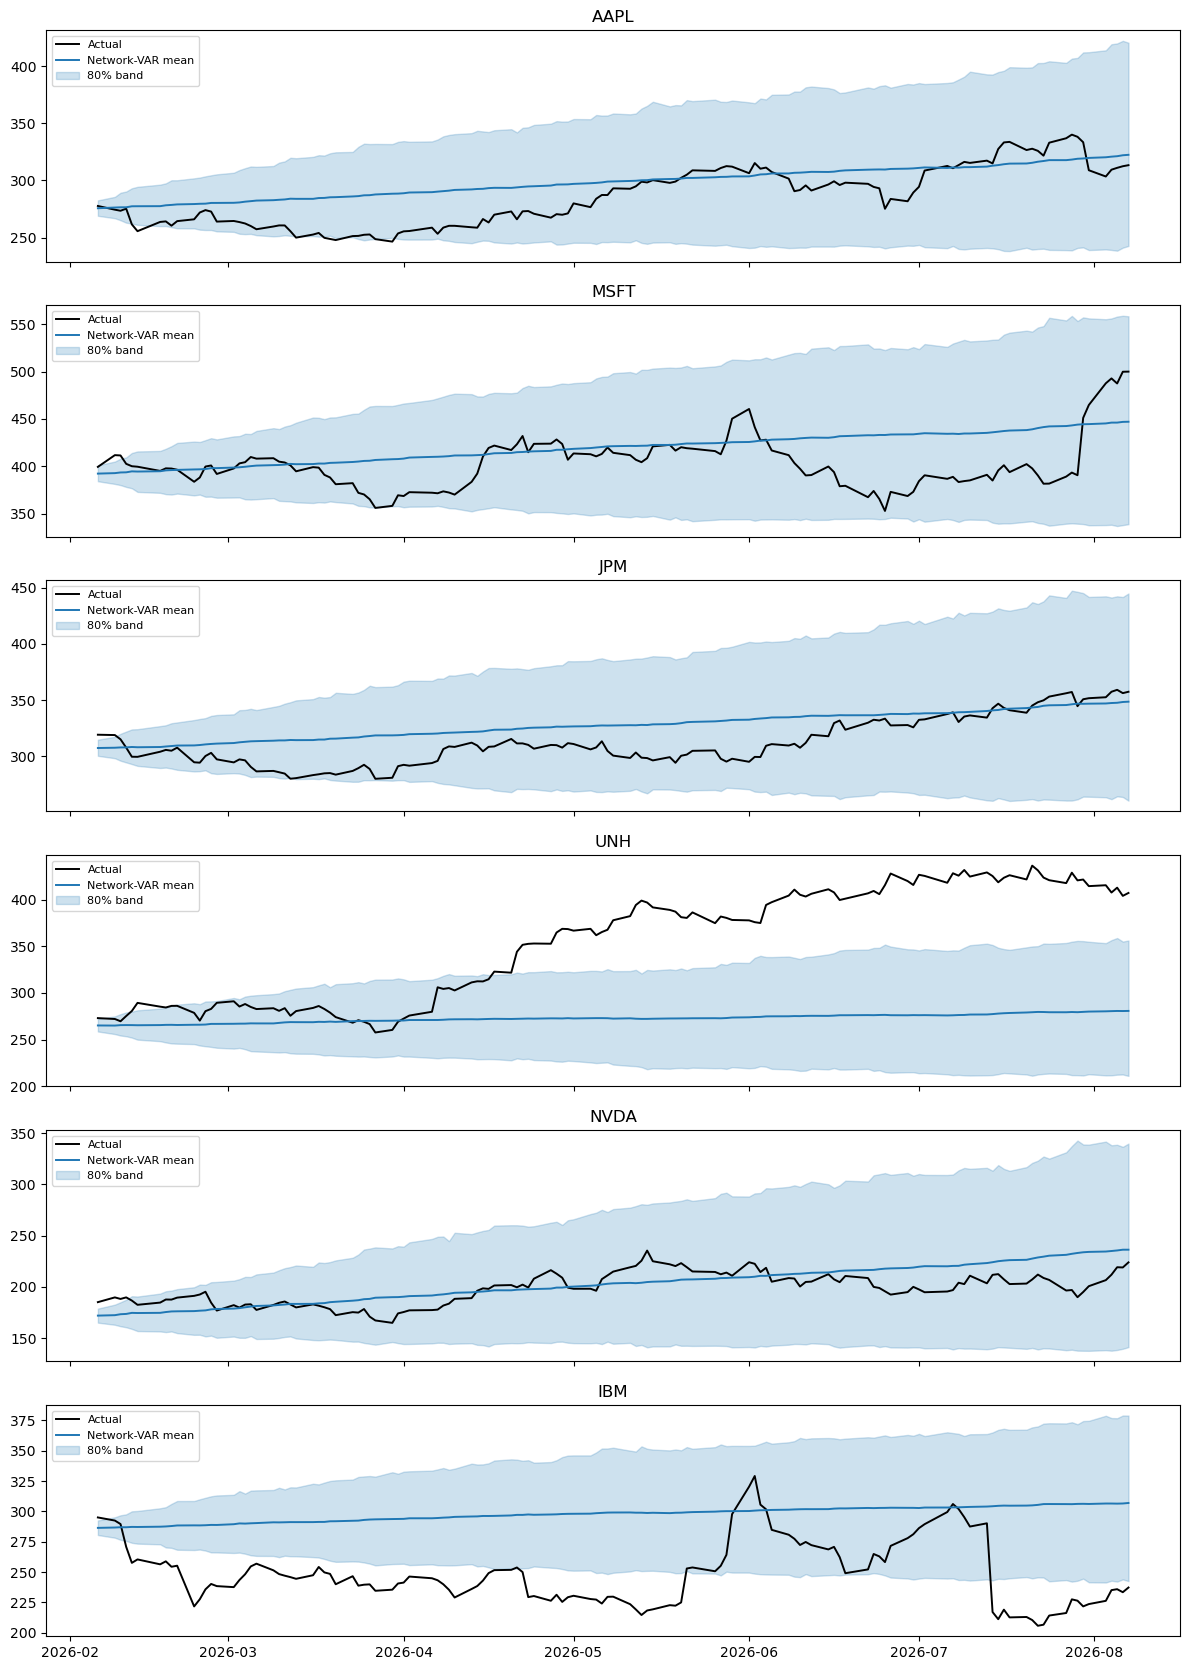

In [20]:
# ------------------------------------------------------------
# 8. Plots
# ------------------------------------------------------------
plot_list = ["AAPL", "MSFT", "JPM", "UNH", "NVDA", "IBM"]
fig, axes = plt.subplots(len(plot_list), 1, figsize=(12, 2.8*len(plot_list)), sharex=True)
for ax, t in zip(axes, plot_list):
    j = tickers.index(t)
    ax.plot(test_prices.index, true_prices[:, j], color="black", lw=1.4, label="Actual")
    ax.plot(test_prices.index, price_mean[:, j], color="C0", lw=1.4, label="Network-VAR mean")
    ax.fill_between(test_prices.index, price_q10[:, j], price_q90[:, j],
                    color="C0", alpha=0.22, label="80% band")
    ax.set_title(t)
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig("djia_6m_network_var_plots.png", dpi=150)
print("Saved: djia_6m_network_var_plots.png")
print("\nDone.")